# MILP

Here we show how to use the naive implementation of a Mixed-Integer
Linear Programming (MILP) Branch & Bound in `bnbprob.milpy`, in which
the LP relaxation of each node is solved with `scipy.optimize.linprog`.
Nodes are branched on fractional variables, by adding the bounds
$x_i \leq \lfloor x_i^* \rfloor$ and $x_i \geq \lceil x_i^* \rceil$.

In [1]:
import numpy as np

from bnbprob.milpy import MILP
from bnbpy import (
    BranchAndBound,
    BreadthFirstBnB,
    plot_tree,
)

## Simple model

The simple model has the form:

$$
\begin{aligned}
    \text{maximize} \quad & 5 x_{1} + 4 x_{2} \\
    \text{subject to} \quad & 2 x_{1} + 3 x_{2} \leq 12 \\
    & 2 x_{1} + x_{2} \leq 6 \\
    & x_{i} \geq 0 & \forall \; i \in \{1, 2\} \\
    & x_{i} \in \mathbb{Z} & \forall \; i \in \{1, 2\}
\end{aligned}
$$

As `MILP` follows the conventions of `linprog` (minimization, constraints
$A_{ub} x \leq b_{ub}$), the objective coefficients are negated:
$c = (-5, -4)$. Thus, the optimal cost $-18$ corresponds to the maximum
value $18$ at $x = (2, 2)$. The optimum of the LP relaxation is $19.5$,
at $x = (1.5, 3)$.

By default, variables are non-negative and integer.

In [2]:
# Simple problem
c = np.array([-5.0, -4.0])

A_ub = np.array(
    [[2.0, 3.0],
     [2.0, 1.0]]
)
b_ub = np.array([12.0, 6.0])

bfs = BreadthFirstBnB(MILP(c, A_ub=A_ub, b_ub=b_ub))
sol = bfs.solve()
print(f"Sol: {sol} | x: {sol.problem.results.x}")
print(f"Nodes explored: {bfs.explored}")

Sol: Status: OPTIMAL | Cost: -18.0 | LB: -18.0 | x: [2. 2.]
Nodes explored: 3


`BranchAndBound` uses a depth-first search by default, which finds the
same solution. The number of explored nodes depends on the strategy.

In [3]:
dfs = BranchAndBound(MILP(c, A_ub=A_ub, b_ub=b_ub))
sol = dfs.solve()
print(f"Sol: {sol} | x: {sol.problem.results.x}")
print(f"Nodes explored: {dfs.explored}")

Sol: Status: OPTIMAL | Cost: -18.0 | LB: -18.0 | x: [2. 2.]
Nodes explored: 4


## Multi-dimensional knapsack

In a two-dimensional knapsack, items $i \in N$ have a value $c_{i}$ and
two sizes, $w_{i}$ and $v_{i}$, limited by the capacities $K_{w}$ and
$K_{v}$. The binary variable $x_{i}$ indicates whether item $i$ is
selected:

$$
\begin{aligned}
    \text{maximize} \quad & \sum_{i \in N} c_{i} x_{i} \\
    \text{subject to} \quad & \sum_{i \in N} w_{i} x_{i} \leq K_{w} \\
    & \sum_{i \in N} v_{i} x_{i} \leq K_{v} \\
    & x_{i} \in \{0, 1\} & \forall \; i \in N
\end{aligned}
$$

Again, the values are negated in the minimization problem.
The tree is saved (`save_tree=True`) to be plotted afterwards.

In [4]:
# Two-dimensional knapsack
np.random.seed(42)

N = 10  # Number of items

# Sizes of each item
w = np.random.normal(loc=5.0, scale=1.0, size=N).clip(0.5, 10.0)
v = np.random.normal(loc=6.0, scale=2.0, size=N).clip(0.5, 10.0)

# Values of each item (negated to minimize)
c = -np.random.normal(loc=10.0, scale=1.0, size=N).clip(0.5, 20.0)

# Knapsack capacities
kw = 21.0
kv = 22.0

A_ub = np.atleast_2d([w, v])
b_ub = np.array([kw, kv])

milp = MILP(c, A_ub=A_ub, b_ub=b_ub, bounds=(0, 1))
bnb = BranchAndBound(milp, save_tree=True)
sol = bnb.solve(maxiter=250)
print(f"Sol: {sol} | {bnb.explored} nodes explored")
print(f"Selected items: {np.flatnonzero(sol.problem.results.x > 0.5)}")

Sol: Status: OPTIMAL | Cost: -41.726493076490556 | LB: -41.726493076490556 | 71 nodes explored
Selected items: [0 1 5 7]


And we can plot the search tree. Each label shows the lower bound of
the node and, as a subscript, its index (order of creation).

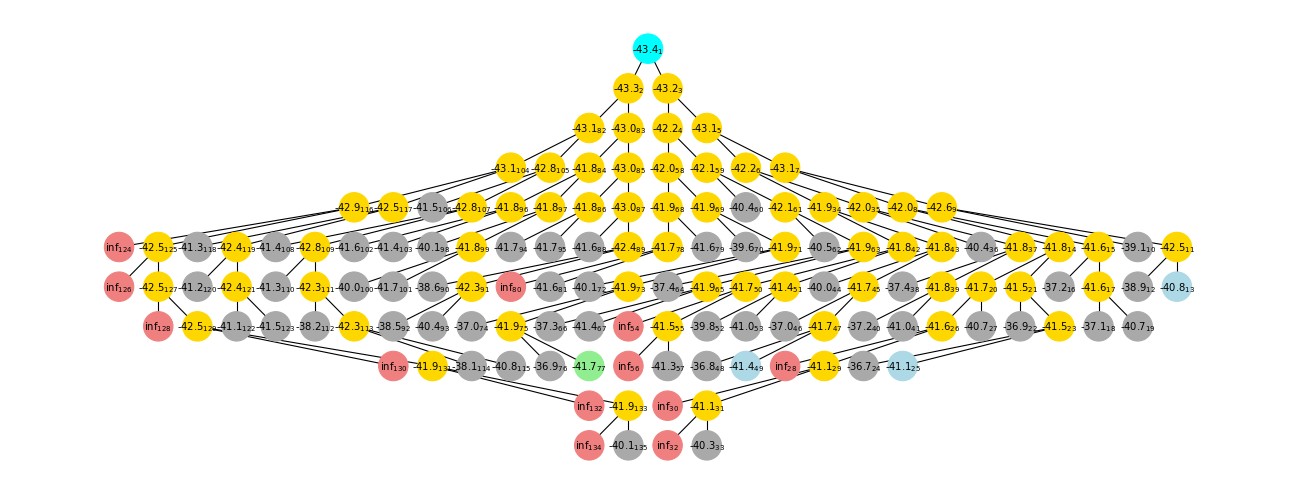

In [5]:
plot_tree(bnb.root, font_size=9, figsize=[16, 6], dpi=80)